<a href="https://colab.research.google.com/github/yongmeiwang/AI_BigData_CancerBiology/blob/main/TCGAmutation_Nov3_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Direct S3 URL provided
url = 'https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/mc3%2FBRCA_mc3.txt.gz'

try:
    print("Downloading and loading dataset from S3...")
    # pandas can read gzipped tab-separated files directly from a URL
    df = pd.read_csv(url, sep='\t', compression='gzip')
    print(f"Successfully loaded dataset! Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Successfully loaded dataset! Shape: (92119, 12)


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
0,TCGA-3C-AAAU-01,10,122668955,122668955,G,A,WDR11,3'UTR,NaN,0.39,NaN,NaN
1,TCGA-3C-AAAU-01,10,8115874,8115875,-,A,GATA3,Frame_Shift_Ins,p.P409Afs*99,0.34,NaN,NaN
2,TCGA-3C-AAAU-01,11,65272906,65272908,AAA,-,MALAT1,RNA,NaN,0.27,NaN,NaN
3,TCGA-3C-AAAU-01,11,66082467,66082467,C,T,CD248,Missense_Mutation,p.E678K,0.07,tolerated(0.12),benign(0.001)
4,TCGA-3C-AAAU-01,11,66193652,66193652,G,C,NPAS4,3'UTR,NaN,0.20,NaN,NaN


In [3]:
TCGA_BRCA_MC3 = df
display(TCGA_BRCA_MC3.head())

,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
0,TCGA-3C-AAAU-01,10,122668955,122668955,G,A,WDR11,3'UTR,NaN,0.39,NaN,NaN
1,TCGA-3C-AAAU-01,10,8115874,8115875,-,A,GATA3,Frame_Shift_Ins,p.P409Afs*99,0.34,NaN,NaN
2,TCGA-3C-AAAU-01,11,65272906,65272908,AAA,-,MALAT1,RNA,NaN,0.27,NaN,NaN
3,TCGA-3C-AAAU-01,11,66082467,66082467,C,T,CD248,Missense_Mutation,p.E678K,0.07,tolerated(0.12),benign(0.001)
4,TCGA-3C-AAAU-01,11,66193652,66193652,G,C,NPAS4,3'UTR,NaN,0.20,NaN,NaN


In [ ]:
unique_samples_count = TCGA_BRCA_MC3['sample'].nunique()
print(f"Total number of unique samples: {unique_samples_count}")

Total number of unique samples: 791


In [ ]:
TCGA_BRCA_MC3.shape

(92119, 12)

Here is what each column in the `TCGA_BRCA_MC3` DataFrame represents:

* **`sample`**: The TCGA barcode identifier for the specific biological sample (e.g., `TCGA-3C-AAAU-01`). The suffix (like `-01`) typically indicates a primary solid tumor.
* **`chr`**: The chromosome where the mutation is located (e.g., `10`, `11`, `X`).
* **`start`**: The 1-based start genomic coordinate position of the mutation on the chromosome.
* **`end`**: The 1-based end genomic coordinate position of the mutation on the chromosome.
* **`reference`**: The normal allele (nucleotide sequence) found in the reference genome at this position (e.g., `G`, `C`, or `-` for insertions).
* **`alt`**: The alternative allele (mutated sequence) found in the tumor sample (e.g., `A`, `T`, or `-` for deletions).
* **`gene`**: The symbol of the gene affected by the mutation (e.g., `GATA3`, `WDR11`, `MALAT1`).
* **`effect`**: The functional impact classification of the mutation on the gene transcript (e.g., `Missense_Mutation`, `Frame_Shift_Ins`, `3'UTR`, `Silent`).
* **`Amino_Acid_Change`**: The resulting change in the protein sequence using standard HGVS nomenclature (e.g., `p.E678K` or `p.P409Afs*99` for a frameshift).
* **`DNA_VAF`**: **Variant Allele Frequency**. The proportion of sequencing reads matching the mutated (alternative) allele versus the reference allele in the DNA sequencing data.
* **`SIFT`**: The prediction score from SIFT (Sorting Intolerant From Tolerant), which estimates whether an amino acid substitution affects protein function (e.g., `tolerated(0.12)` or `deleterious`).
* **`PolyPhen`**: The prediction score from PolyPhen-2 (Polymorphism Phenotyping v2), which predicts the possible impact of an amino acid substitution on the structure and function of a human protein (e.g., `benign(0.001)` or `probably_damaging`).

In [4]:
# Calculate the number of unique mutated genes in the dataset
unique_genes_count = TCGA_BRCA_MC3['gene'].nunique()
print(f"Total number of unique mutated genes: {unique_genes_count}")

Total number of unique mutated genes: 18065


/tmp/ipykernel_990/1735555918.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')


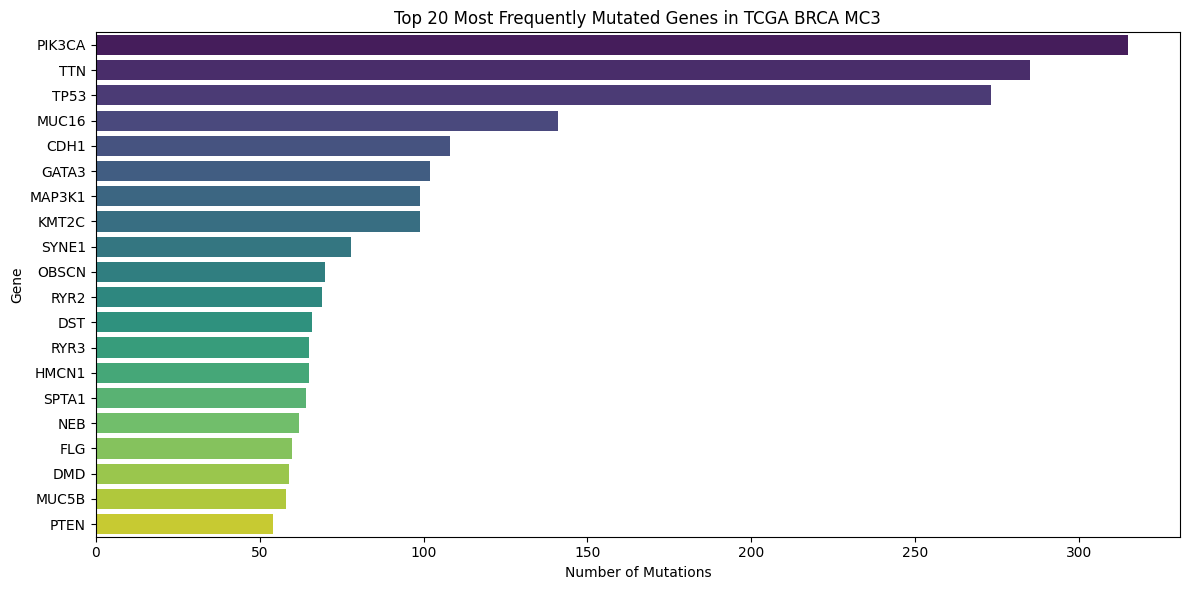

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count mutation frequency per gene
gene_mutation_counts = TCGA_BRCA_MC3['gene'].value_counts().reset_index()
gene_mutation_counts.columns = ['gene', 'mutation_count']

# Get the top 20 most frequently mutated genes
top_20_genes = gene_mutation_counts.head(20)

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')
plt.title('Top 20 Most Frequently Mutated Genes in TCGA BRCA MC3')
plt.xlabel('Number of Mutations')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

,mutation_type,count,percentage
0,Missense_Mutation,45634,49.538097
1,Silent,17122,18.586828
2,Frame_Shift_Del,8522,9.251077
3,3'UTR,6695,7.267773
4,Nonsense_Mutation,3666,3.979635
5,Intron,3212,3.486794
6,5'UTR,2492,2.705197
7,Splice_Site,1399,1.518688
8,RNA,1160,1.259241
9,Frame_Shift_Ins,610,0.662187


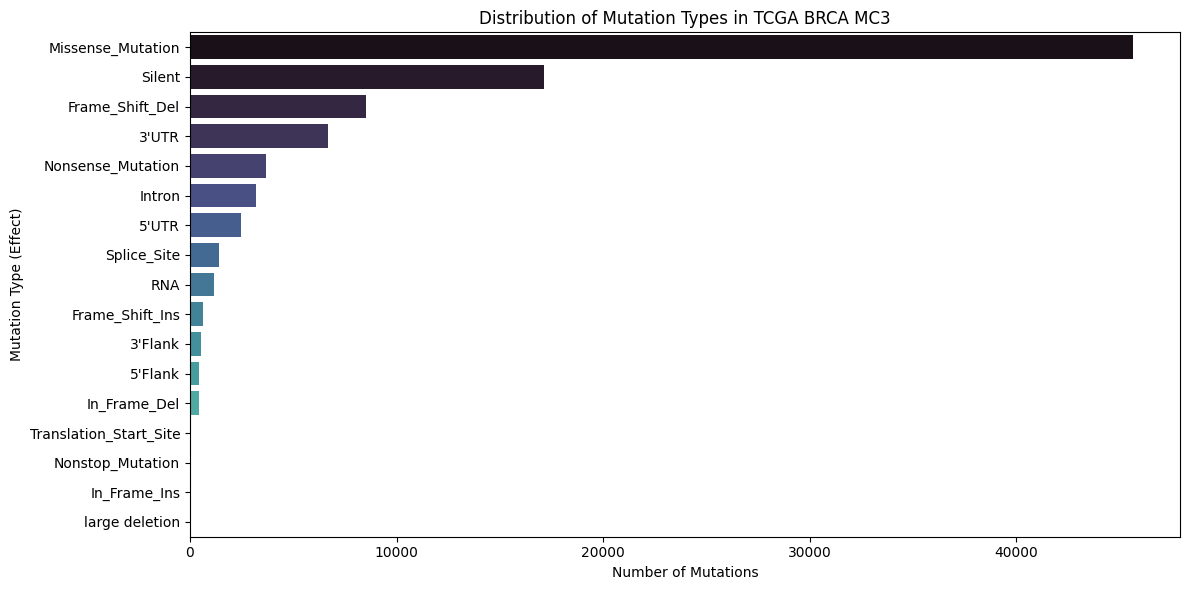

In [6]:
# Calculate the frequency of each mutation effect (type of mutation)
effect_counts = TCGA_BRCA_MC3['effect'].value_counts().reset_index()
effect_counts.columns = ['mutation_type', 'count']
effect_counts['percentage'] = (effect_counts['count'] / effect_counts['count'].sum()) * 100

# Display the mutation types and their frequencies
display(effect_counts)

# Create a visualization of the mutation types
plt.figure(figsize=(12, 6))
sns.barplot(data=effect_counts, x='count', y='mutation_type', hue='mutation_type', legend=False, palette='mako')
plt.title('Distribution of Mutation Types in TCGA BRCA MC3')
plt.xlabel('Number of Mutations')
plt.ylabel('Mutation Type (Effect)')
plt.tight_layout()
plt.show()

# Explanation of Mutation Types (Effects) in TCGA_BRCA_MC3
These terms describe how each genomic mutation affects the transcription and translation of the target gene:

### Coding / Protein-Altering Mutations (Nonsynonymous):

* **`Missense_Mutation`**: A point mutation where a single nucleotide change results in a codon that codes for a different amino acid (e.g., changing Glutamic acid to Lysine). This may alter the protein's folding, stability, or activity.
* **`Nonsense_Mutation`**: A mutation that changes an amino acid codon into a premature translation termination codon (stop codon), resulting in a truncated, usually non-functional protein.
* **`Frame_Shift_Del / Frame_Shift_Ins`**: Deletions or insertions of nucleotides that are not multiples of three. This shifts the downstream reading frame, radically changing the protein sequence from that point onward and often introducing a premature stop codon.
* **`In_Frame_Del / In_Frame_Ins`**: Deletions or insertions of nucleotides in multiples of three. This removes or adds amino acids without altering the reading frame of the rest of the protein.
* **`Translation_Start_Site / Nonstop_Mutation`**: Mutations that disrupt the start codon (preventing translation initiation) or destroy the normal stop codon (causing translation to continue past the normal end of the transcript).

### Non-Protein-Altering Mutations (Synonymous):

* **`Silent`**: A mutation that changes a codon to another codon that translates to the exact same amino acid. These usually do not alter the protein structure but can sometimes impact translation speed.

### Splice & Regulatory Region Mutations:

* **`Splice_Site`**: Mutations located at the junction of introns and exons. These can disrupt the precise splicing of pre-mRNA, causing exons to be skipped or introns to be retained.
* **`3'UTR / 5'UTR` (Untranslated Regions)**: Mutations in the mRNA regions that are not translated into protein. These regions contain critical binding sites for microRNAs and regulatory proteins that control transcript stability and translation rate.
* **`Intron`**: Mutations occurring within the non-coding introns. While mostly benign, they can occasionally affect splicing enhancers or regulatory elements.
* **`3'Flank / 5'Flank`**: Mutations located upstream (5') or downstream (3') of the gene locus, potentially affecting promoter or enhancer regions.

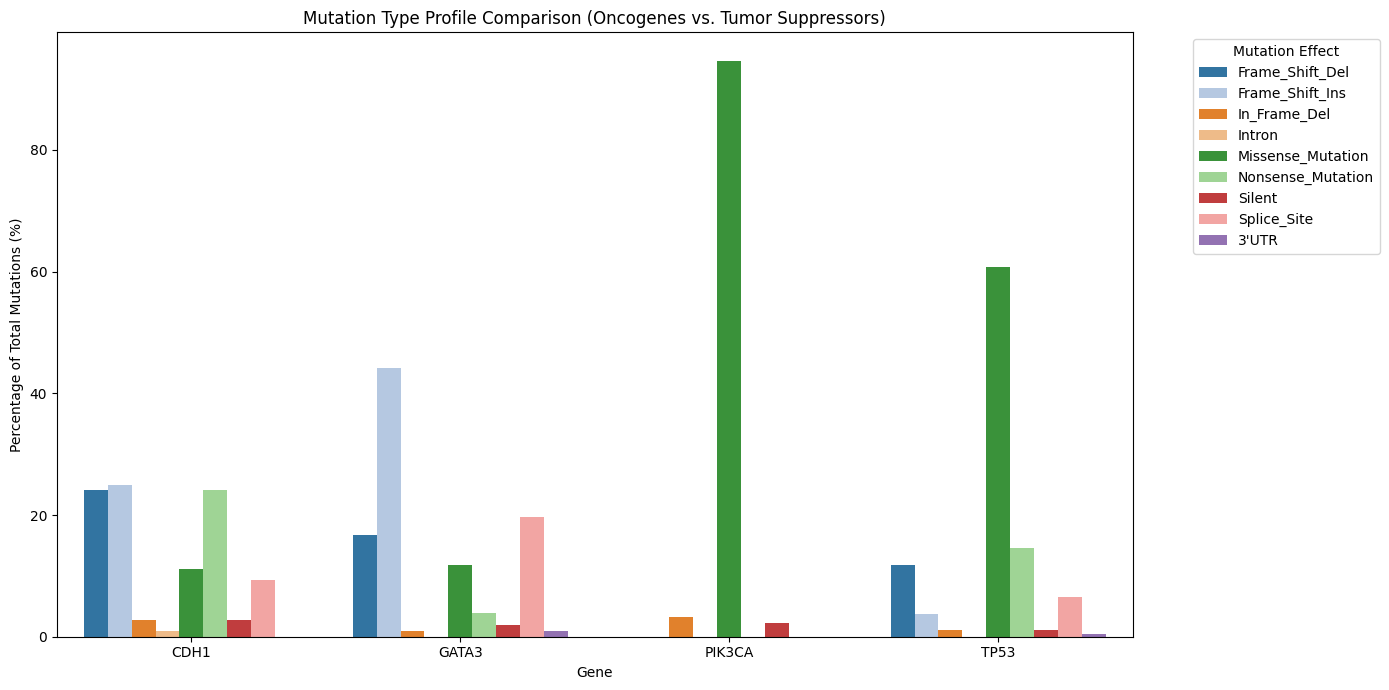

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select key genes of interest (Oncogenes vs Tumor Suppressors)
selected_genes = ['PIK3CA', 'TP53', 'CDH1', 'GATA3']

# Filter dataset for these genes
df_filtered = TCGA_BRCA_MC3[TCGA_BRCA_MC3['gene'].isin(selected_genes)]

# Calculate counts of each mutation type (effect) per gene
gene_effect_counts = df_filtered.groupby(['gene', 'effect']).size().reset_index(name='count')

# Calculate percentages within each gene for fair comparison
gene_totals = df_filtered.groupby('gene').size().reset_index(name='total')
gene_effect_counts = gene_effect_counts.merge(gene_totals, on='gene')
gene_effect_counts['percentage'] = (gene_effect_counts['count'] / gene_effect_counts['total']) * 100

# Plot the comparison
plt.figure(figsize=(14, 7))
sns.barplot(
    data=gene_effect_counts,
    x='gene',
    y='percentage',
    hue='effect',
    palette='tab20'
)

plt.title('Mutation Type Profile Comparison (Oncogenes vs. Tumor Suppressors)')
plt.xlabel('Gene')
plt.ylabel('Percentage of Total Mutations (%)')
plt.legend(title='Mutation Effect', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Biological Interpretation of the Mutation Profiles

These four highly mutated genes represent two fundamentally opposite biological mechanisms in breast cancer: **Oncogenes** (which drive cell growth) and **Tumor Suppressor Genes** (which normally inhibit cell growth).

### 1. Oncogenes (The "Accelerator")
* **`PIK3CA`**:
  * **Classification**: Classical Oncogene.
  * **Role**: Codes for a catalytic subunit of the PI3K enzyme, which transmits crucial signals for cell survival, proliferation, and growth.
  * **Mutation Profile**: Dominated almost entirely by **`Missense_Mutation`** (>90%).
  * **Why?**: To promote cancer, the gene requires a specific, single amino acid alteration that locked the protein into a permanently "active" or "on" state. Completely disrupting or truncating the protein (which would happen with a frameshift or nonsense mutation) would instead deactivate it, offering no growth advantage to the tumor.

### 2. Tumor Suppressor Genes (The "Brakes")
Unlike oncogenes, these genes serve as checkpoints to prevent uncontrolled division. Cancer cells benefit from mutating these genes in ways that completely break or deactivate them ("loss-of-function").

* **`TP53`**:
  * **Classification**: Master Tumor Suppressor ("Guardian of the Genome").
  * **Role**: Arrests cell cycle progression and activates DNA repair or programmed cell death (apoptosis) in response to cellular stress or DNA damage.
  * **Mutation Profile**: A mix of **`Missense_Mutation`** (~60%), **`Nonsense_Mutation`** (~15%), and **`Frame_Shift_Del`** (~12%). Many of the missense mutations in TP53 actually act in a dominant-negative fashion to poison the active p53 tetramers, while the truncations completely deplete functioning protein.

* **`CDH1`**:
  * **Classification**: Tumor Suppressor (Adhesion Molecule).
  * **Role**: Encodes E-cadherin, a protein responsible for cell-to-cell adhesion. Intact E-cadherin keeps cells clustered together; its loss allows tumor cells to separate and metastasize.
  * **Mutation Profile**: Dominated by destructive **`Frame_Shift_Del`** and **`Frame_Shift_Ins`** mutations. These frame modifications result in premature translation termination and a complete absence of stable E-cadherin on the cell surface.

* **`GATA3`**:
  * **Classification**: Tumor Suppressor (Transcription Factor).
  * **Role**: A key regulator of mammary gland development and luminal cell differentiation.
  * **Mutation Profile**: Highly enriched for **`Frame_Shift_Ins`** and **`Splice_Site`** mutations. Frameshifts near the C-terminus produce altered protein structures that fail to bind DNA properly, preventing cellular differentiation and allowing unchecked proliferation.

In [ ]:
# Get a list of all unique values in the 'effect' column
unique_effects = TCGA_BRCA_MC3['effect'].value_counts(dropna=False)
print("All unique values in the 'effect' column and their counts:")
display(unique_effects)

All unique values in the 'effect' column and their counts:


,count
effect,
Missense_Mutation,45634
Silent,17122
Frame_Shift_Del,8522
3'UTR,6695
Nonsense_Mutation,3666
Intron,3212
5'UTR,2492
Splice_Site,1399
RNA,1160


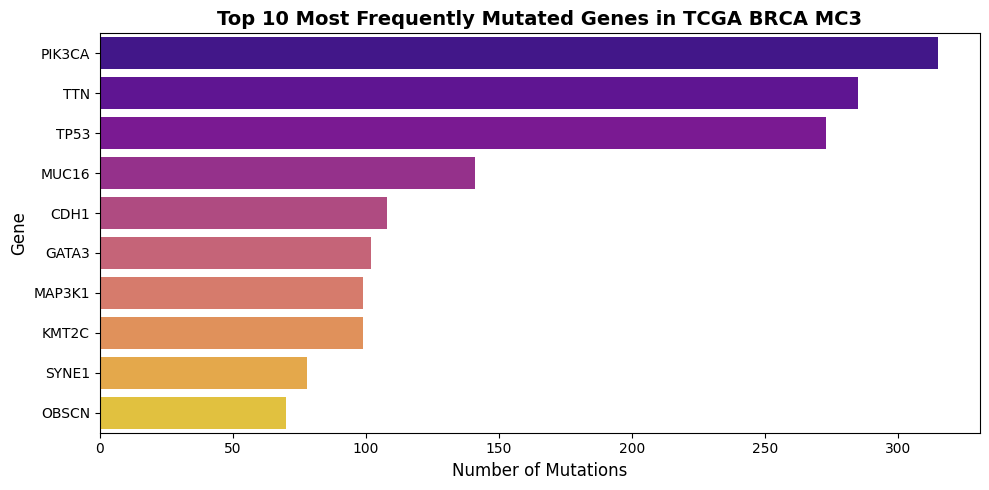

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count mutation frequency per gene
gene_counts = TCGA_BRCA_MC3['gene'].value_counts().reset_index()
gene_counts.columns = ['gene', 'mutation_count']

# Get the top 10 most mutated genes
top_10_genes = gene_counts.head(10)

# Create the visualization
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_10_genes,
    x='mutation_count',
    y='gene',
    hue='gene',
    legend=False,
    palette='plasma'
)

plt.title('Top 10 Most Frequently Mutated Genes in TCGA BRCA MC3', fontsize=14, fontweight='bold')
plt.xlabel('Number of Mutations', fontsize=12)
plt.ylabel('Gene', fontsize=12)
plt.tight_layout()
plt.show()